# Exploratory Data Analysis

## Drone Delivery On-Time Prediction

This notebook performs a focused EDA for a drone delivery classification problem. The aim is not to analyze every possible variable exhaustively, but to identify the most useful information for building a machine learning model that predicts whether a delivery arrives on time.

The analysis focuses on:

1. Dataset structure  
2. Data quality  
3. Target distribution  
4. Key numerical and categorical predictors  
5. Simple interpretable feature engineering  
6. Correlation with the target  
7. Final EDA summary  


## 1. Import libraries

Loads the libraries used throughout the notebook — `pandas`/`numpy` for data handling, `matplotlib`/`seaborn` for plotting — and sets a few display options. `pd.set_option` widens the number of columns/rows pandas prints, so wide tables (many features) don't get silently truncated while exploring the data. `FIGURES_DIR` is created up front so every plot in the notebook can be saved consistently to one place for later reuse in reports or presentations.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

try:
    import seaborn as sns
except ImportError:
    raise ImportError("Please install seaborn: pip install seaborn")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

FIGURES_DIR = Path("../figures/eda")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


## 2. Load the data

The notebook supports both Excel and CSV files.

Expected location:

```text
data/raw/
    train.xlsx or train.csv
    test.xlsx or test.csv
    sample_submission.xlsx or sample_submission.csv
```

Kaggle-style datasets are sometimes distributed as `.csv` and sometimes as `.xlsx`. Trying multiple extensions here means the notebook doesn't break just because of a file-format detail, and it fails with a clear error message instead of a confusing one if a file is genuinely missing.


In [2]:
DATA_DIR = Path("../data/raw")

def load_table(file_stem, data_dir=DATA_DIR):
    possible_files = [
        data_dir / f"{file_stem}.xlsx",
        data_dir / f"{file_stem}.xls",
        data_dir / f"{file_stem}.csv",
    ]

    for path in possible_files:
        if path.exists():
            print(f"Loading: {path}")
            if path.suffix.lower() in [".xlsx", ".xls"]:
                return pd.read_excel(path)
            return pd.read_csv(path)

    raise FileNotFoundError(
        f"Could not find {file_stem}.xlsx, {file_stem}.xls, or {file_stem}.csv in {data_dir.resolve()}"
    )

train = load_table("train")
test = load_table("test")
sample_submission = load_table("sample_submission")

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Sample submission shape:", sample_submission.shape)

train.head()


Loading: ..\data\raw\train.csv
Loading: ..\data\raw\test.csv
Loading: ..\data\raw\sample_submission.csv
Train shape: (40000, 11)
Test shape: (10000, 10)
Sample submission shape: (10000, 2)


,Id,distance_km,payload_kg,drone_model,slot_15min,wind_token,route_turns,alt_profile,landing_zone,operator_tag,on_time
0,1662,3.498,2.676,B,75,S-0/4,UUUUURLUD,0-0-0-0-1-1-1-1-1,LZ-146,safe,1
1,4591,2.209,1.480,B,30,SE-3/5,LLLULLLULLLDLUUULUUU,1-1-1-2-2-2-2-3-2-1-2-3-2-1-1-2-3-2-3-3,LZ-278,balanced,0
2,38756,1.876,0.267,A,26,N-3/5,RRURDDDRDDDRRURDRDRD,0-0-0-1-1-1-1-0-1-1-2-2-2-3-3-3-3-3-3-3,LZ-108,balanced,0
3,31027,1.496,0.510,A,9,E-10/18,LLDDDDLDDRDDRDDDDDDD,0-1-0-0-0-1-2-2-2-2-2-2-3-3-3-3-3-3-3-3,LZ-243,balanced,0
4,1642,2.041,0.240,B,52,SW-11/19,DRRDRRRURDRRDDLDDLDR,1-1-1-1-1-1-2-2-2-2-2-2-2-1-1-1-2-2-2-2,LZ-030,safe,0


## 3. Dataset overview

This section checks the size of the dataset, column types and basic descriptive statistics — how many rows/columns, which columns are numeric vs. categorical, and whether any column's dtype looks wrong (e.g. a numeric column read in as text). This shapes every downstream decision: which columns need parsing, which need encoding, and roughly what preprocessing the modeling pipeline will require.


In [3]:
print("Train columns:")
print(train.columns.tolist())

print("\nData types:")
display(train.dtypes.to_frame("dtype"))

print("\nDataset info:")
train.info()

display(train.describe(include="all").T)


Train columns:
['Id', 'distance_km', 'payload_kg', 'drone_model', 'slot_15min', 'wind_token', 'route_turns', 'alt_profile', 'landing_zone', 'operator_tag', 'on_time']

Data types:


,dtype
Id,int64
distance_km,float64
payload_kg,float64
drone_model,object
slot_15min,int64
wind_token,object
route_turns,object
alt_profile,object
landing_zone,object
operator_tag,object



Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Id            40000 non-null  int64  
 1   distance_km   40000 non-null  float64
 2   payload_kg    40000 non-null  float64
 3   drone_model   40000 non-null  object 
 4   slot_15min    40000 non-null  int64  
 5   wind_token    40000 non-null  object 
 6   route_turns   40000 non-null  object 
 7   alt_profile   40000 non-null  object 
 8   landing_zone  40000 non-null  object 
 9   operator_tag  40000 non-null  object 
 10  on_time       40000 non-null  int64  
dtypes: float64(2), int64(3), object(6)
memory usage: 3.4+ MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Id,40000.0,NaN,NaN,NaN,24976.84885,14444.341883,1.0,12456.75,24963.5,37479.25,50000.0
distance_km,40000.0,NaN,NaN,NaN,2.252589,1.009084,0.5,1.376,2.249,3.131,4.0
payload_kg,40000.0,NaN,NaN,NaN,0.887531,0.771172,0.102,0.29,0.46,1.431,3.0
drone_model,40000,3,A,17986,NaN,NaN,NaN,NaN,NaN,NaN,NaN
slot_15min,40000.0,NaN,NaN,NaN,47.2296,27.700016,0.0,23.0,47.0,71.0,95.0
wind_token,40000,1553,NE-11/17,63,NaN,NaN,NaN,NaN,NaN,NaN,NaN
route_turns,40000,37473,RRRRRRRR,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
alt_profile,40000,33878,0-0-0-0-0-0-0-0-0,123,NaN,NaN,NaN,NaN,NaN,NaN,NaN
landing_zone,40000,300,LZ-037,159,NaN,NaN,NaN,NaN,NaN,NaN,NaN
operator_tag,40000,3,balanced,17282,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Data quality

This section checks missing values and duplicate rows. Since this is a competition-style dataset, we expect it to be clean, but this should still be verified. Missing values determine whether we need imputation (and which strategy), and duplicate rows — especially duplicate `Id` values — would indicate a data problem that could bias both training and evaluation if left unnoticed.


In [4]:
missing_summary = pd.DataFrame({
    "missing_count": train.isna().sum(),
    "missing_percent": train.isna().mean() * 100
}).sort_values("missing_count", ascending=False)

display(missing_summary)

print("Duplicate rows:", train.duplicated().sum())
print("Duplicate train Id values:", train["Id"].duplicated().sum())
print("Duplicate test Id values:", test["Id"].duplicated().sum())


,missing_count,missing_percent
Id,0,0.0
distance_km,0,0.0
payload_kg,0,0.0
drone_model,0,0.0
slot_15min,0,0.0
wind_token,0,0.0
route_turns,0,0.0
alt_profile,0,0.0
landing_zone,0,0.0
operator_tag,0,0.0


Duplicate rows: 0
Duplicate train Id values: 0
Duplicate test Id values: 0


## 5. Target distribution

The target variable is `on_time`.

- `1`: delivery arrived on time  
- `0`: delivery did not arrive on time  

The balance between classes drives several later decisions: if the classes are imbalanced, accuracy alone becomes a misleading metric (this is why the final evaluation also reports ROC-AUC and PR-AUC), and the modeling pipeline uses `class_weight="balanced"` specifically to compensate for this imbalance during training.


,count,percent
on_time,,
0,16084,40.21
1,23916,59.79


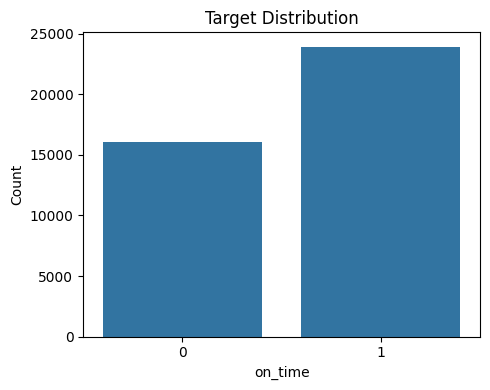

In [5]:
target_counts = train["on_time"].value_counts().sort_index()
target_percent = train["on_time"].value_counts(normalize=True).sort_index() * 100

target_table = pd.DataFrame({
    "count": target_counts,
    "percent": target_percent.round(2)
})

display(target_table)

plt.figure(figsize=(5, 4))
sns.countplot(data=train, x="on_time")
plt.title("Target Distribution")
plt.xlabel("on_time")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "target_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


## 6. Numerical features

The main original numerical variables are:

- `distance_km`
- `payload_kg`

These are likely to be important because longer distances and heavier payloads can increase delivery difficulty. The histogram shows whether a feature is skewed or has outliers (relevant for whether the Logistic Regression pipeline's scaling step is appropriate), and the boxplot split by target shows whether the feature actually separates on-time from late deliveries at all.


,count,mean,std,min,25%,50%,75%,max
distance_km,40000.0,2.252589,1.009084,0.500,1.376,2.249,3.131,4.0
payload_kg,40000.0,0.887531,0.771172,0.102,0.290,0.460,1.431,3.0


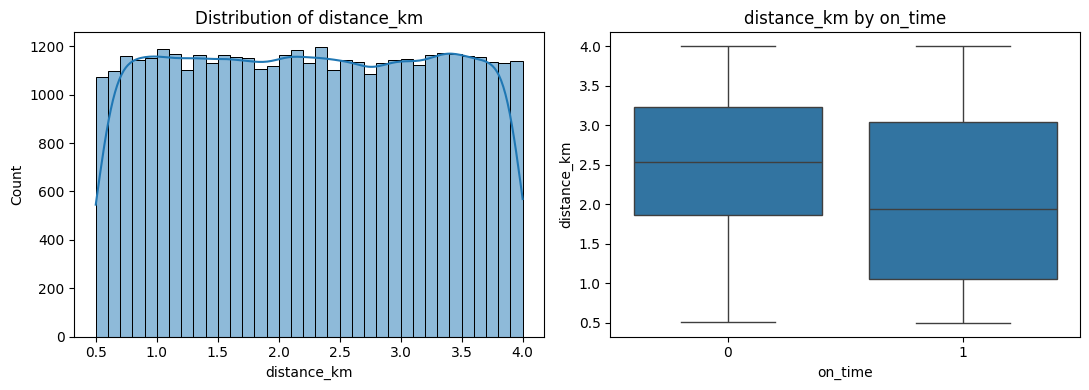

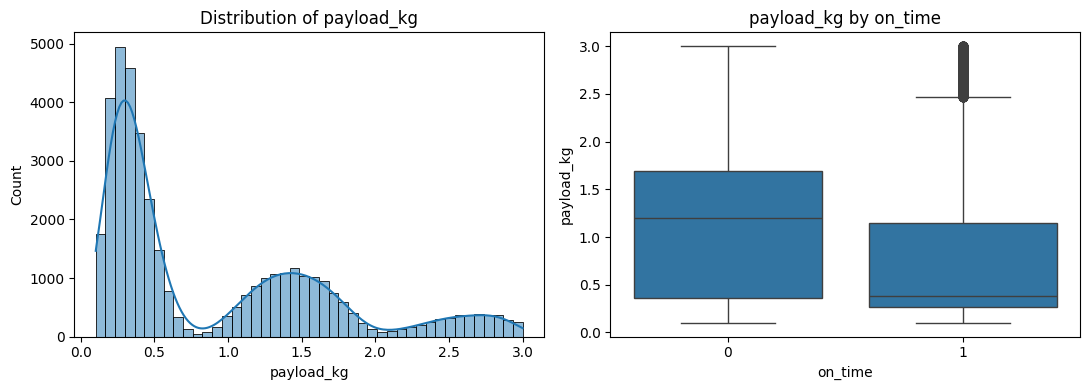

In [6]:
num_cols = ["distance_km", "payload_kg"]

display(train[num_cols].describe().T)

for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    sns.histplot(train[col], kde=True, ax=axes[0])
    axes[0].set_title(f"Distribution of {col}")

    sns.boxplot(data=train, x="on_time", y=col, ax=axes[1])
    axes[1].set_title(f"{col} by on_time")

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{col}_eda.png", dpi=300, bbox_inches="tight")
    plt.show()


## 7. Categorical features

The most important low-cardinality categorical variables are:

- `drone_model`
- `operator_tag`

For each variable, we inspect both its frequency and the average on-time rate per category. Frequency shows whether every category has enough data to produce a reliable estimate (a category with only a handful of rows can show a misleadingly extreme on-time rate), and the on-time rate per category is what eventually shows up as the model's learned coefficients for these dummy variables.

`aggressive` operators show the highest on-time rate and `safe` operators the lowest. This was checked against a possible confound (whether aggressive operators are simply dispatched on shorter/lighter/simpler missions) — mean and median `distance_km`, `payload_kg`, `route_length`, `direction_changes`, `mean_altitude`, and `altitude_changes` are essentially identical across the three `operator_tag` groups, so the effect is not explained by route assignment differences.



drone_model frequency:


,count
drone_model,
A,17986
B,14015
C,7999



drone_model on-time rate:


,count,mean
drone_model,,
B,14015,0.700107
C,7999,0.547818
A,17986,0.540532


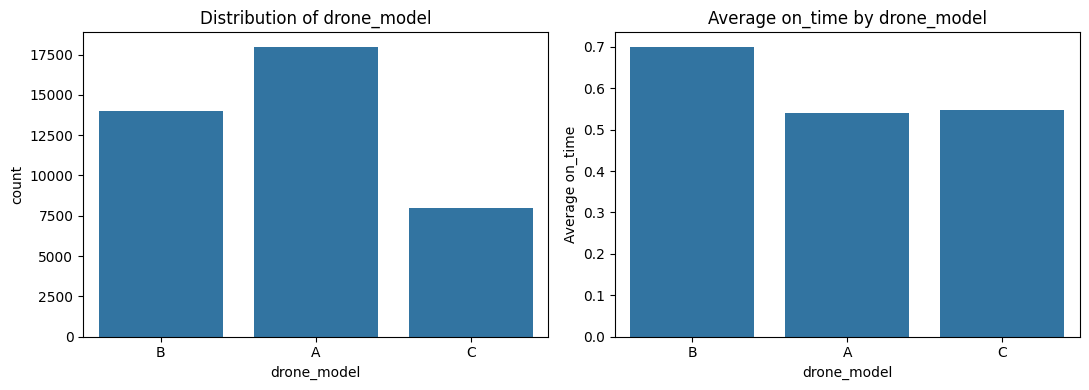


operator_tag frequency:


,count
operator_tag,
balanced,17282
safe,15677
aggressive,7041



operator_tag on-time rate:


,count,mean
operator_tag,,
aggressive,7041,0.683568
balanced,17282,0.626316
safe,15677,0.528098


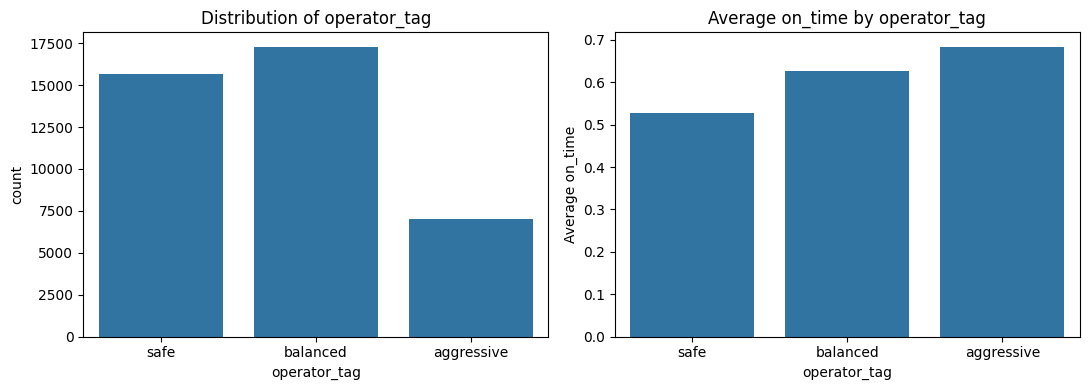

In [7]:
cat_cols = ["drone_model", "operator_tag"]

for col in cat_cols:
    print(f"\n{col} frequency:")
    display(train[col].value_counts().to_frame("count"))

    print(f"\n{col} on-time rate:")
    rate_table = train.groupby(col)["on_time"].agg(["count", "mean"]).sort_values("mean", ascending=False)
    display(rate_table)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    sns.countplot(data=train, x=col, ax=axes[0])
    axes[0].set_title(f"Distribution of {col}")

    sns.barplot(data=train, x=col, y="on_time", errorbar=None, ax=axes[1])
    axes[1].set_title(f"Average on_time by {col}")
    axes[1].set_ylabel("Average on_time")

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{col}_eda.png", dpi=300, bbox_inches="tight")
    plt.show()


## 8. Feature Engineering for Exploratory Analysis

Some variables are stored as compact strings. In this section they are transformed into simple, interpretable numerical features that can be explored before model development.

The analysis is divided into three parts:

- **8.1 Wind Features**
- **8.2 Route Features**
- **8.3 Altitude Features**

`wind_token`, `route_turns`, and `alt_profile` are packed into single string columns (e.g. `"NE-12/18"`, a sequence of turn characters, `"120-140-120"`), which a model can't use directly. Parsing them into numeric features (wind speed/gust, route length and number of direction changes, mean altitude and number of altitude changes) turns raw encoded strings into information the model can actually learn from. This exploratory version mirrors the logic in `src/feature_engineering.py`'s `DroneFeatureEngineer`, which does the same parsing inside the production pipeline.


In [8]:
# Wind features
wind = train["wind_token"].str.extract(
    r"(?P<wind_direction>[A-Z]+)-(?P<wind_avg>\d+)/(?P<wind_gust>\d+)"
)

train["wind_direction"] = wind["wind_direction"]
train["wind_avg"] = wind["wind_avg"].astype(int)
train["wind_gust"] = wind["wind_gust"].astype(int)

# Route features
def count_direction_changes(route):
    return sum(route[i] != route[i - 1] for i in range(1, len(route)))

train["route_length"] = train["route_turns"].str.len()
train["direction_changes"] = train["route_turns"].apply(count_direction_changes)

# Altitude features
def parse_altitude(profile):
    return list(map(int, str(profile).split("-")))

altitudes = train["alt_profile"].apply(parse_altitude)

train["mean_altitude"] = altitudes.apply(np.mean)
train["altitude_changes"] = altitudes.apply(lambda x: sum(x[i] != x[i - 1] for i in range(1, len(x))))

engineered_cols = [
    "wind_direction", "wind_avg", "wind_gust",
    "route_length", "direction_changes",
    "mean_altitude", "altitude_changes"
]

display(train[["wind_token", "route_turns", "alt_profile"] + engineered_cols].head())
display(train[["wind_avg", "wind_gust", "route_length", "direction_changes", "mean_altitude", "altitude_changes"]].describe().T)


,wind_token,route_turns,alt_profile,wind_direction,wind_avg,wind_gust,route_length,direction_changes,mean_altitude,altitude_changes
0,S-0/4,UUUUURLUD,0-0-0-0-1-1-1-1-1,S,0,4,9,4,0.555556,1
1,SE-3/5,LLLULLLULLLDLUUULUUU,1-1-1-2-2-2-2-3-2-1-2-3-2-1-1-2-3-2-3-3,SE,3,5,20,9,1.950000,12
2,N-3/5,RRURDDDRDDDRRURDRDRD,0-0-0-1-1-1-1-0-1-1-2-2-2-3-3-3-3-3-3-3,N,3,5,20,13,1.650000,5
3,E-10/18,LLDDDDLDDRDDRDDDDDDD,0-1-0-0-0-1-2-2-2-2-2-2-3-3-3-3-3-3-3-3,E,10,18,20,7,1.900000,5
4,SW-11/19,DRRDRRRURDRRDDLDDLDR,1-1-1-1-1-1-2-2-2-2-2-2-2-1-1-1-2-2-2-2,SW,11,19,20,13,1.550000,3


,count,mean,std,min,25%,50%,75%,max
wind_avg,40000.0,6.997250,4.068686,0.0,3.0,7.0,11.00,14.00
wind_gust,40000.0,13.799400,4.841941,2.0,10.0,14.0,17.00,27.00
route_length,40000.0,17.716825,3.828486,8.0,16.0,20.0,20.00,20.00
direction_changes,40000.0,7.524225,3.053759,0.0,5.0,7.0,10.00,17.00
mean_altitude,40000.0,1.375662,0.707093,0.0,0.8,1.4,1.95,2.85
altitude_changes,40000.0,5.256275,2.270116,0.0,4.0,5.0,7.00,15.00


## 9. Engineered features vs target

This section checks whether the engineered features appear useful for predicting on-time delivery — plotting each one against `on_time` is a quick check that we're not just adding noise (and unnecessary model complexity) for features that turn out not to matter.


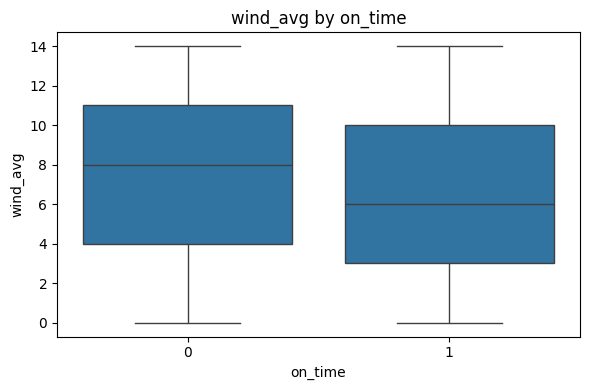

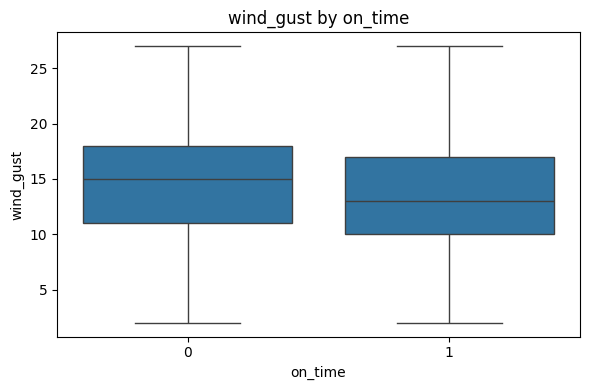

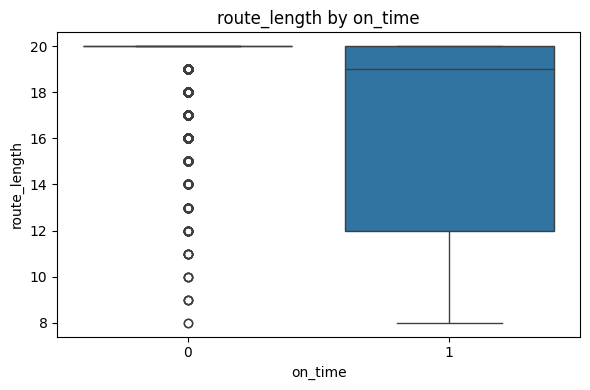

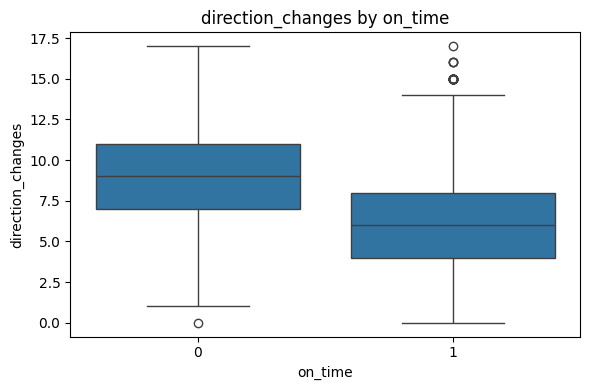

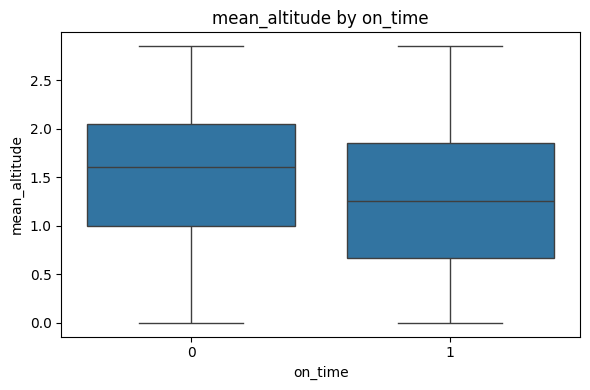

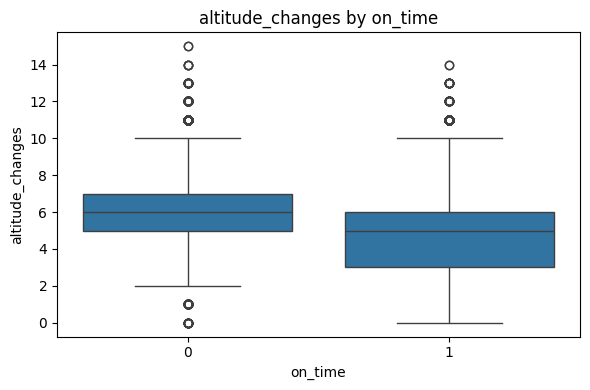

Wind direction on-time rate:


,count,mean
wind_direction,,
E,4906,0.614554
N,5005,0.610390
NE,5108,0.606304
NW,4970,0.598592
S,4977,0.594937
SE,5040,0.592063
SW,4959,0.583787
W,5035,0.582721


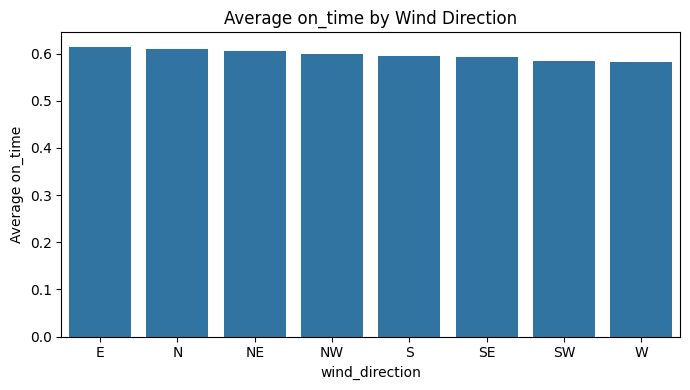

In [9]:
engineered_num_cols = [
    "wind_avg", "wind_gust",
    "route_length", "direction_changes",
    "mean_altitude", "altitude_changes"
]

for col in engineered_num_cols:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=train, x="on_time", y=col)
    plt.title(f"{col} by on_time")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{col}_by_target.png", dpi=300, bbox_inches="tight")
    plt.show()

print("Wind direction on-time rate:")
display(train.groupby("wind_direction")["on_time"].agg(["count", "mean"]).sort_values("mean", ascending=False))

plt.figure(figsize=(7, 4))
sns.barplot(data=train, x="wind_direction", y="on_time", errorbar=None, order=sorted(train["wind_direction"].unique()))
plt.title("Average on_time by Wind Direction")
plt.ylabel("Average on_time")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "wind_direction_on_time_rate.png", dpi=300, bbox_inches="tight")
plt.show()


## 10. Correlation with the target

A simple correlation analysis helps identify which numerical variables have the strongest linear relationship with `on_time`. This gives a fast, single-number ranking of which numeric features look most related to the outcome, though it only captures **linear** relationships — a feature could still matter a lot to a tree-based model (which can pick up non-linear patterns) even if its correlation with the target looks weak here.


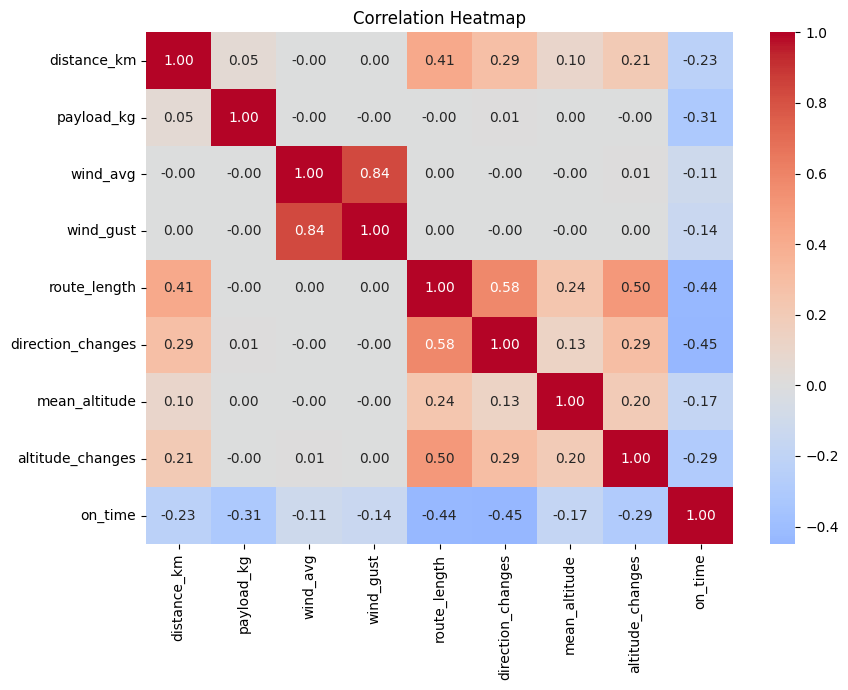

,correlation_with_on_time
on_time,1.000000
wind_avg,-0.114706
wind_gust,-0.144134
mean_altitude,-0.173067
distance_km,-0.230943
altitude_changes,-0.287584
payload_kg,-0.308777
route_length,-0.438448
direction_changes,-0.449630


In [10]:
corr_cols = [
    "distance_km", "payload_kg",
    "wind_avg", "wind_gust",
    "route_length", "direction_changes",
    "mean_altitude", "altitude_changes",
    "on_time"
]

corr = train[corr_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

display(corr["on_time"].sort_values(ascending=False).to_frame("correlation_with_on_time"))


`wind_avg` and `wind_gust` show a moderately high correlation (~0.84) in this data, since gust speed naturally scales with average wind speed. Both are kept in the model rather than dropping one: gust intensity captures a distinct, turbulence-related risk that average wind speed alone doesn't, and the model's L2 regularization handles the shared information between correlated features by shrinking their coefficients together rather than requiring manual feature removal.
